# 4. Any number of independent models, without pooling raw biases

One run is the core workflow. Repeat it for one, four, or any number of models.
Each trajectory has its own COLVAR and its own bias zero. Do not concatenate raw
independently shifted biases and apply one global normalization.

This executable example uses four **synthetic** biased ensembles to demonstrate
common-reference FES alignment. It is not a physical four-MLP result.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from bivo4_fes import *

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
OUT = ROOT / "results"
OUT.mkdir(exist_ok=True)

/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
TEMPERATURE = 350.0
kBT = TEMPERATURE * 8.617333262145e-5
surfaces = []
run_observables = []
for run, a in enumerate([0.040, 0.042, 0.038, 0.041]):
    rng = np.random.default_rng(run)
    q = rng.normal(scale=np.sqrt(kBT/a), size=(2500, 2))
    # Deliberately different arbitrary bias offsets between runs.
    bias = -0.5*a*np.sum(q*q, axis=1) + 5.0*run
    lw = opes_logweights(bias, temperature=TEMPERATURE, unit="eV")
    surfaces.append(compute_fes(q, lw, bounds=[[-1.2, 1.2], [-1.2, 1.2]],
                                bins=81, bandwidth=.12, method="local"))
    run_observables.append((q, lw))
mean, spread = average_fes(surfaces, reference=[0.0, 0.0])
print("Runs:", len(surfaces))
print("Mean/spread use only common finite support.")

Runs: 4
Mean/spread use only common finite support.


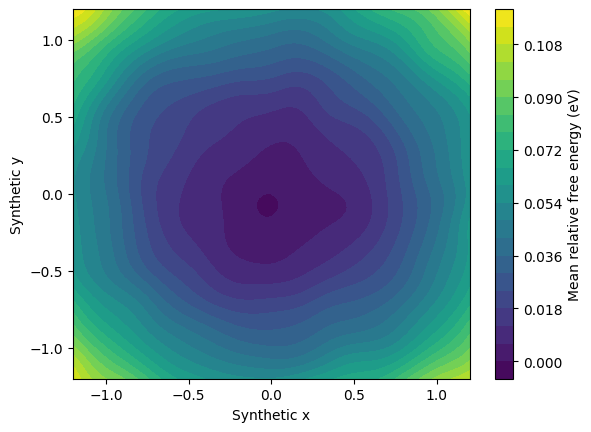

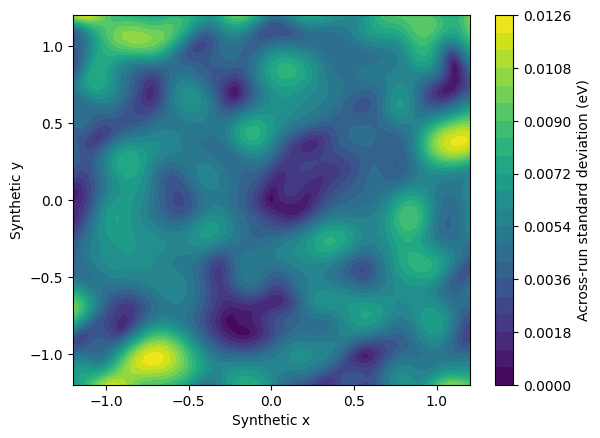

In [3]:
fig, ax = plt.subplots()
artist = ax.contourf(*surfaces[0].axes, mean.T, levels=20)
fig.colorbar(artist, ax=ax, label="Mean relative free energy (eV)")
ax.set(xlabel="Synthetic x", ylabel="Synthetic y")
plt.show()

fig, ax = plt.subplots()
artist = ax.contourf(*surfaces[0].axes, spread.T, levels=20)
fig.colorbar(artist, ax=ax, label="Across-run standard deviation (eV)")
ax.set(xlabel="Synthetic x", ylabel="Synthetic y")
plt.show()

The arithmetic mean is a descriptive model/run average. Its standard deviation
(ddof=0) is not a standard error, and the mean is not the FES of a single physical
Hamiltonian. Alignment at a common coordinate avoids hiding differences by
independently choosing four different zero-energy basin minima.

Within-run variation and between-model variation should be inspected separately.

Full-run weighted categories: {'left': 0.5151120431006648, 'right': 0.48488795689933595}
Contiguous blocks: [{'left': 0.5567005383560746, 'right': 0.4432994616439253}, {'left': 0.4800641471765285, 'right': 0.5199358528234717}, {'left': 0.49435326135983243, 'right': 0.5056467386401674}, {'left': 0.5270646899452586, 'right': 0.47293531005474093}]
Weight concentration: {'frames': 2500, 'kish_ess': 1879.9323803692646, 'largest_weight_fraction': 0.0008045023928593775}


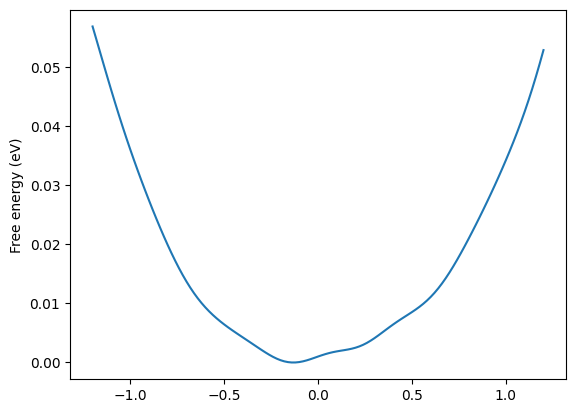

In [4]:
q, lw = run_observables[0]
labels = np.where(q[:,0] < 0, "left", "right")
print("Full-run weighted categories:", populations(labels, lw))
print("Contiguous blocks:", block_populations(labels, lw, nblocks=4))
print("Weight concentration:", weight_diagnostics(lw))

# A 1D projection uses the same generic FES function and original frame weights.
f1 = compute_fes(q[:,0], lw, bounds=[-1.2, 1.2], bins=121, bandwidth=.12)
f1.plot()
plt.show()

## A transparent production wrapper

The function below processes one run and returns surfaces. Use `run_one(...)`
on its own, or in a loop over runs. It does not launch background processes.
A changed selection should have a new cache filename; cached metadata records
the actual selection used. Production geometry can be generated in an earlier
job and reloaded here.

This example assumes a `total_bias` column and the original CV names `d1,cn`.
Adapt the explicit bias expression for a deliberately restrained target ensemble.

In [5]:
def run_one(trajectory, colvar_path, cache, *, cell, timestep_ps,
            acceptors, discard_before_ps, rebuild=False):
    cache = Path(cache)
    if rebuild or not cache.exists():
        selection = PTSelection.from_symbols(xyz_symbols(trajectory), donor=151,
                                             acceptors=acceptors, index_base=1)
        frames = iter_xyz(trajectory, cell=cell, timestep_ps=timestep_ps)
        pt = analyze(frames, selection, cv_acceptor=130, progress=False)
        pt.save(cache)
    else:
        pt = PTResult.load(cache)
    c = read_colvar(colvar_path)
    rows = align_colvar(pt.time, c)
    check_cv_alignment(pt, c, rows)
    lw = opes_logweights(c["total_bias"][rows], temperature=350, unit="kJ/mol")
    keep = pt.time >= discard_before_ps
    answer = {}
    for name in ("direct", "indirect"):
        q = pt.channel(name)
        if np.any(keep & pt.valid(name)):
            answer[name] = compute_fes(
                np.column_stack((q["delta"], q["distance"]))[keep], lw[keep],
                bounds=[[-1.5, 1.5], [2.3, 3.5]], bins=[301, 201],
                bandwidth=[.03, .03], temperature=350, unit="eV")
    return pt, answer

# One run:
# pt0, surfaces0 = run_one(...)
# Four runs (or any other number):
# results = [run_one(**settings) for settings in your_run_settings]
# mean, std = average_fes([r[1]["direct"] for r in results], reference=your_reference)

## Reuse other tools without inheriting the whole project

- **ECToolkits legacy arrays:** columns 1/2 are delta/dOO in the supplied notebook.
  Feed these into `compute_fes` to preserve the legacy definition while replacing
  KDE. `benchmarks/compare_legacy.py` checks new geometry against saved outputs.
- **PLUMED driver:** recompute any fixed/dynamic CV with your validated input;
  `read_colvar` and `compute_fes` handle its new named columns with the OLD original
  bias values. `write_colvar` also exports tables for PLUMED READ.
- **MDAnalysis:** use `iter_mdanalysis` for your Universe, including LAMMPS/XTC/DCD.
- **ASE:** supply `Frame(index, atoms.positions, as_box(atoms.cell.array), ...)`
  from your own streaming ASE iterator. Keep the time/step mapping explicit.

Future 1D/2D observables need not know anything about proton transfer. Compute one
value per saved configuration, match its original bias, and call the same FES
function. Periodic angular CVs require periodic kernels, not the current
nonperiodic KDE. Actual kinetic rates require a separate valid kinetics method.